In [1]:
#Install the packages we need 

%pip install -q huggingface_hub pyarrow pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
#Import the Python libraries we need 

from huggingface_hub import hf_hub_download

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#Download the Beginner dataset 

file_path = hf_hub_download(
    repo_id="RGES-PIT/Beginner",
    filename="RMDC26_Beginner_Tier_test.parquet",
    repo_type="dataset"
)

#print the location of the downloaded file on your computer 
print(file_path)

RMDC26_Beginner_Tier_test.parquet: reconstructing file:   0%|          |  0.00B /  165MB            

RMDC26_Beginner_Tier_test.parquet: downloading bytes:           |  0.00B            

/Users/maihaller/.cache/huggingface/hub/datasets--RGES-PIT--Beginner/snapshots/3d091e68f83662a843c9a5ef78b913c1b0e30848/RMDC26_Beginner_Tier_test.parquet


In [6]:
#Load in a select few colunmns, the ones you think will be most important 
## Name = event/target ID
## Bjd = time of the observation 
## filt = Roman filter 
## mag = measured magnitude 
## mag_err = uncertainity in that magnitude 
## saturation_flag = whether that measurement was saturated (0 = good, 1 = saturated) 

df = pd.read_parquet(
    file_path,
    columns=[
        "name",
        "bjd",
        "filt",
        "mag",
        "mag_err",
        "saturation_flag"
    ]
)

df.head()

,name,bjd,filt,mag,mag_err,saturation_flag
0,RMDC26_000001,2.461448e+06,F087,22.453972,0.081850,0
1,RMDC26_000001,2.461448e+06,F087,22.561998,0.090412,0
2,RMDC26_000001,2.461448e+06,F087,22.444434,0.081134,0
3,RMDC26_000001,2.461449e+06,F087,22.445701,0.081228,0
4,RMDC26_000001,2.461449e+06,F087,22.371004,0.075828,0


In [7]:
#Check how much data we have 

print("Number of observations:", len(df))
print("Number of targets:", df["name"].nunique())

Number of observations: 9230048
Number of targets: 188


In [8]:
#Let's pull ONE event now 

event_name = df["name"].iloc[0]

event = df[df["name"] == event_name].copy()

print(event_name)
print(len(event))

event.head()

RMDC26_000001
49096


,name,bjd,filt,mag,mag_err,saturation_flag
0,RMDC26_000001,2.461448e+06,F087,22.453972,0.081850,0
1,RMDC26_000001,2.461448e+06,F087,22.561998,0.090412,0
2,RMDC26_000001,2.461448e+06,F087,22.444434,0.081134,0
3,RMDC26_000001,2.461449e+06,F087,22.445701,0.081228,0
4,RMDC26_000001,2.461449e+06,F087,22.371004,0.075828,0


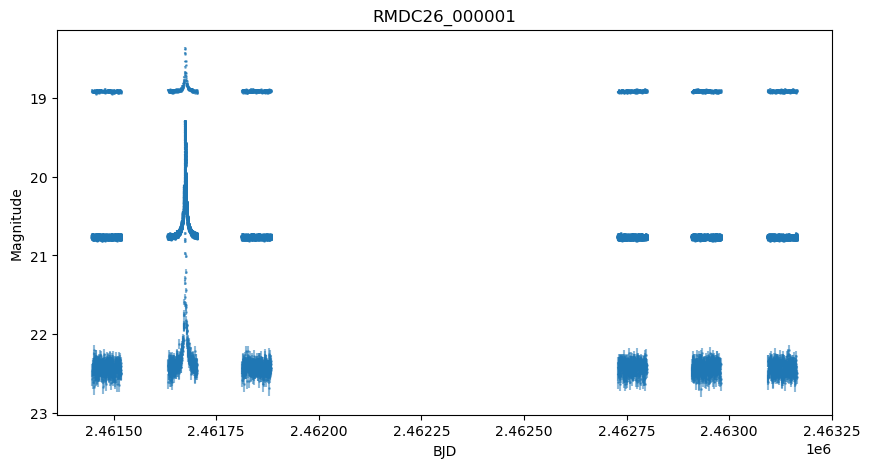

In [9]:
#Plot this event 

plt.figure(figsize=(10, 5))

plt.errorbar(
    event["bjd"],
    event["mag"],
    yerr=event["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

plt.xlabel("BJD")
plt.ylabel("Magnitude")
plt.title(event_name)

plt.gca().invert_yaxis()

plt.show()

In [10]:
# Look at all of the different filters used to observe this target.
#
# .unique() returns each distinct value that appears
# in the "filt" column.

event["filt"].unique()

array(['F087', 'F146', 'F213'], dtype=object)

In [11]:
# Count how many observations we have in each filter.
#
# value_counts() tells us how many rows belong
# to each distinct filter.

event["filt"].value_counts()

filt
F146    46208
F087     1445
F213     1443
Name: count, dtype: int64

In [ ]:
#Target was observed in 3 filters 

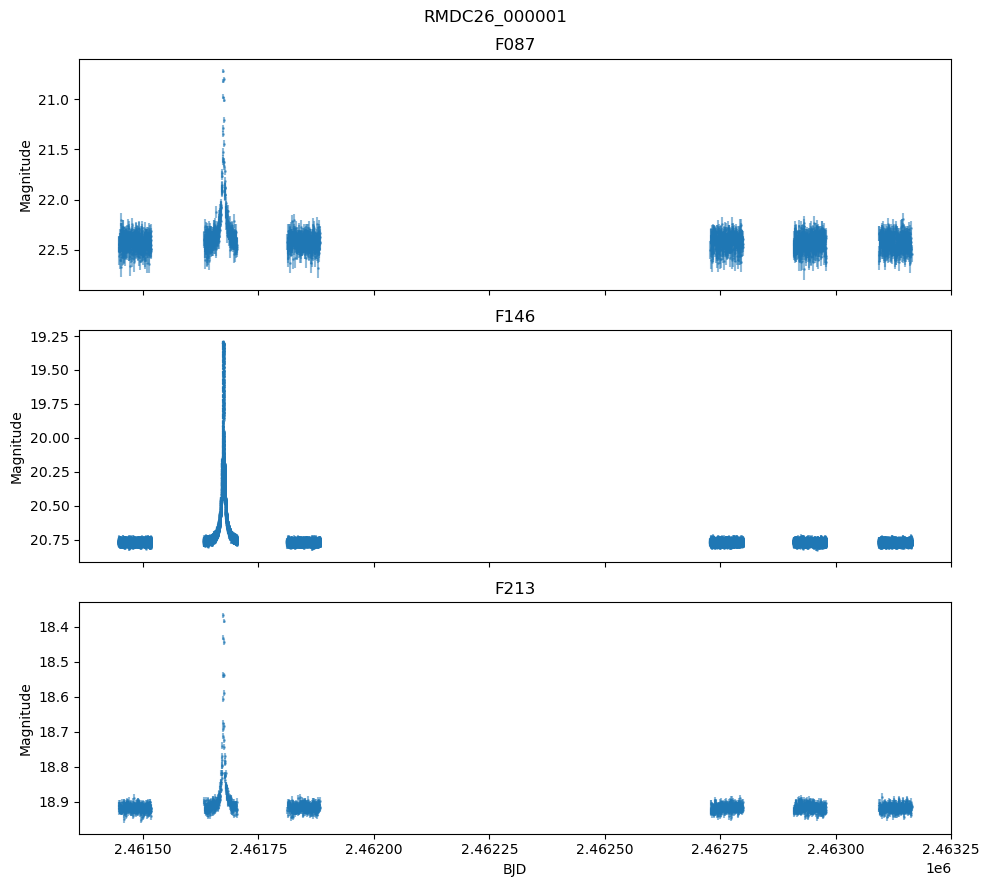

In [21]:
#Let's separate the filters

F087_data = event[event["filt"] == "F087"]
F146_data = event[event["filt"] == "F146"]
F213_data = event[event["filt"] == "F213"]


#Create 3 plots stacked vertically

#nrows = 3 means we want 3 rows of plots
#ncols = 1 means we want one plot per row
#sharex = True means all plots use the same BJD/time axis

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 9),
    sharex=True
)


#Plot F087

axes[0].errorbar(
    F087_data["bjd"],
    F087_data["mag"],
    yerr=F087_data["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

axes[0].set_ylabel("Magnitude")
axes[0].set_title("F087")
axes[0].invert_yaxis()


#Plot F146

axes[1].errorbar(
    F146_data["bjd"],
    F146_data["mag"],
    yerr=F146_data["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

axes[1].set_ylabel("Magnitude")
axes[1].set_title("F146")
axes[1].invert_yaxis()


#Plot F213

axes[2].errorbar(
    F213_data["bjd"],
    F213_data["mag"],
    yerr=F213_data["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

axes[2].set_ylabel("Magnitude")
axes[2].set_title("F213")
axes[2].invert_yaxis()


#Label the shared x-axis

axes[2].set_xlabel("BJD")


#Add the event name as the overall title

fig.suptitle(event_name)


#Fix spacing so labels do not overlap

plt.tight_layout()


#Display the plots

plt.show()

In [ ]:
#Basic workflow

#1) Understand + clean data <-- where we are now
#2) Fit every target first with the simplest 1S1L model 
#3) Inspect residuals and decide whether 1S1L is adequate 
#4) Classify targets by the models they require 
#5) Fit more complicated events appropriately 
    #binary lens (1S2L), binary source (2S1L), finite-source/parallax effects when needed
#6) Build one results table for all 188 targets
#7) Save diagnostic plots and document methodogloy/computation 
#8) Run everything through microlens-submit validation 

In [ ]:
Wordle 1,930 6/6

⬜🟨🟨⬜⬜
🟨🟨⬜⬜⬜
⬜🟩🟩⬜🟨
🟩🟩⬜⬜⬜
🟩🟩🟩⬜⬜
🟩🟩🟩🟩🟩

In [22]:
#Check how many saturated and unsaturated observations
#we have in each filter

event.groupby(["filt", "saturation_flag"]).size()

filt  saturation_flag
F087  0                   1445
F146  0                  46208
F213  0                   1443
dtype: int64

In [ ]:
#None of the measurements are saturated! That's good! 

#We can start estimating the model parameters 

#Start fitting F146 because it has the most observations 

In [23]:
#Get an initial guess for t0 (time when the mircolensing event reaches maximum brightness)

#Select only F146 observations

F146_data = event[event["filt"] == "F146"].copy()


#Find the row with the smallest magnitude

#idxmin() gives us the row where mag is smallest
#Smallest magnitude = brightest observation

brightest_index = F146_data["mag"].idxmin()


#Get the BJD of the brightest observation

t0_guess = F146_data.loc[brightest_index, "bjd"]


#Get the magnitude at the brightest observation

peak_mag = F146_data.loc[brightest_index, "mag"]


#Print our first estimate for the event peak

print("t0 guess:", t0_guess)
print("Peak magnitude:", peak_mag)

t0 guess: 2461674.3704177
Peak magnitude: 19.29032655752838


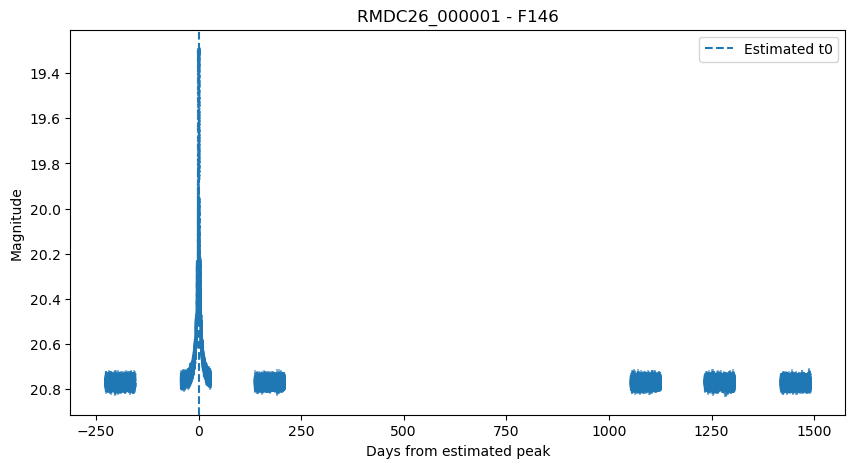

In [24]:
#Create a new column for time relative to our estimated peak

#At the peak, relative_time = 0
#Before the peak = negative time
#After the peak = positive time

F146_data["relative_time"] = F146_data["bjd"] - t0_guess


#Plot the F146 light curve relative to the peak

plt.figure(figsize=(10, 5))

plt.errorbar(
    
    #Time relative to the event peak
    F146_data["relative_time"],
    
    #Measured magnitude
    F146_data["mag"],
    
    #Magnitude uncertainty
    yerr=F146_data["mag_err"],
    
    #Plot observations as small dots
    fmt=".",
    markersize=2,
    alpha=0.5
)


#Label the axes

plt.xlabel("Days from estimated peak")
plt.ylabel("Magnitude")


#Add a title

plt.title(event_name + " - F146")max


#Smaller magnitude = brighter

plt.gca().invert_yaxis()


#Mark our estimated t0

#x = 0 because we defined the peak as relative_time = 0

plt.axvline(
    x=0,
    linestyle="--",
    label="Estimated t0"
)


#Show the label for the dashed line

plt.legend()


#Display the plot

plt.show()

RMDC26_000009
RMDC26_000009
49096


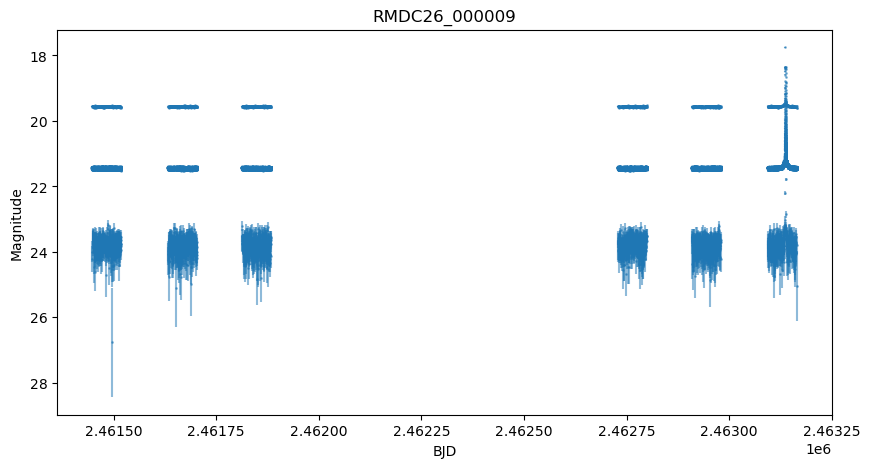

In [27]:

event_name = df["name"].iloc[424242]

print(event_name)

event = df[df["name"] == event_name].copy()

print(event_name)
print(len(event))

event.head()


plt.figure(figsize=(10, 5))

plt.errorbar(
    event["bjd"],
    event["mag"],
    yerr=event["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

plt.xlabel("BJD")
plt.ylabel("Magnitude")
plt.title(event_name)

plt.gca().invert_yaxis()

plt.show()

In [62]:
kk = 0

RMDC26_000050
t0 guess: 2461693.0890261
Peak magnitude: 16.752138636004865


/var/folders/87/9hyfwjnn3jg0bhvrkc4kkggw0000gn/T/ipykernel_52704/4237947090.py:117: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


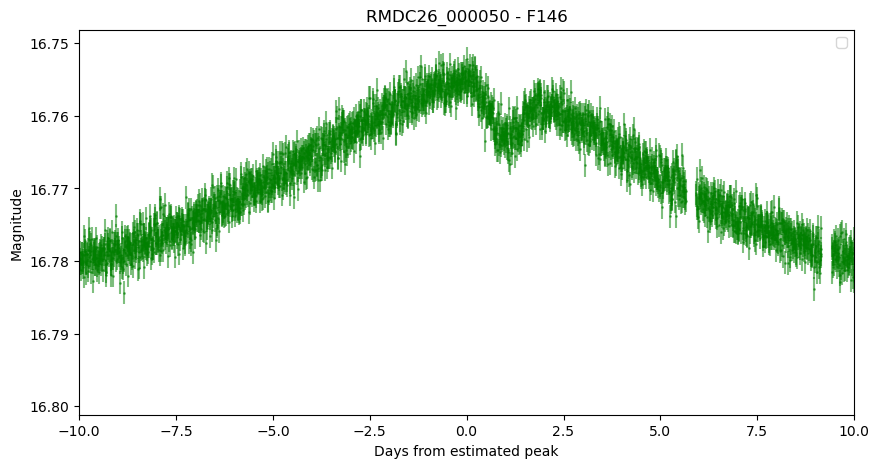

65


In [138]:
#RAPID FIRE

#kk -= 1 

e_names = list(set(df.name))

event_name = e_names[kk] 

#event_name = df["name"].iloc[424242]

print(event_name)

event = df[df["name"] == event_name].copy()



#Create a new column for time relative to our estimated peak

#At the peak, relative_time = 0
#Before the peak = negative time
#After the peak = positive time

F146_data = event[event["filt"] == "F146"].copy()

#Get an initial guess for t0 (time when the mircolensing event reaches maximum brightness)

#Select only F146 observations

F146_data = event[event["filt"] == "F146"].copy()


#Find the row with the smallest magnitude

#idxmin() gives us the row where mag is smallest
#Smallest magnitude = brightest observation

brightest_index = F146_data["mag"].idxmin()


#Get the BJD of the brightest observation

t0_guess = F146_data.loc[brightest_index, "bjd"]


#Get the magnitude at the brightest observation

peak_mag = F146_data.loc[brightest_index, "mag"]


#Print our first estimate for the event peak

print("t0 guess:", t0_guess)
print("Peak magnitude:", peak_mag)

F146_data["relative_time"] = F146_data["bjd"] - t0_guess


#Get the BJD of the brightest observation

t0_guess = F146_data.loc[brightest_index, "bjd"]


#Plot the F146 light curve relative to the peak

plt.figure(figsize=(10, 5))

plt.errorbar(
    
    #Time relative to the event peak
    F146_data["relative_time"],
    
    #Measured magnitude
    F146_data["mag"],
    
    #Magnitude uncertainty
    yerr=F146_data["mag_err"],
    
    #Plot observations as small dots
    fmt=".",
    markersize=2,
    alpha=0.5,
    color = "green"
)


#Label the axes

plt.xlabel("Days from estimated peak")
plt.ylabel("Magnitude")


#Add a title

plt.title(event_name + " - F146")


#Smaller magnitude = brighter

plt.gca().invert_yaxis()


#Mark our estimated t0

#x = 0 because we defined the peak as relative_time = 0

#plt.axvline(
   # x=t0_guess,
   # linestyle="--",
   # label="Estimated t0"
#)

plt.xlim(-10, 10)


#Show the label for the dashed line

plt.legend()


#Display the plot

plt.show()

print(kk)

kk+=1

In [64]:
#single
#000002
#000163

#binary
#000178
#000051
#000091 (Free planet?)
#000108 (dimming event, planet?) 
#000051 (planet) 
#000122 (textbook event)
#000016 (caustic?) 
#000014
#000036
#000095 
#000006 (dimming) 
#000049 
#000003 (dimming) 
#000009
#000025
#000133
#000005 (crazy)
#000096
#000037
#000031
#000184 
#000039
#000113
#000099
#000019
#000026 (crazy)
#000176 (horns) 
#000050

#undetermined
#000078
#000027
#000104
#000024
#000035
#000162
#000137




#split into groups, horns, dimming, brightening, spikes, singles 
#if extra time, fit lens models to it 

In [54]:
print(len(df))

#Unique event names
print(len(set(df.name)))

print((set(df.name)))

9230048
188
{'RMDC26_000002', 'RMDC26_000078', 'RMDC26_000084', 'RMDC26_000163', 'RMDC26_000165', 'RMDC26_000178', 'RMDC26_000038', 'RMDC26_000123', 'RMDC26_000061', 'RMDC26_000077', 'RMDC26_000023', 'RMDC26_000051', 'RMDC26_000091', 'RMDC26_000108', 'RMDC26_000114', 'RMDC26_000122', 'RMDC26_000016', 'RMDC26_000151', 'RMDC26_000014', 'RMDC26_000036', 'RMDC26_000080', 'RMDC26_000095', 'RMDC26_000159', 'RMDC26_000006', 'RMDC26_000049', 'RMDC26_000003', 'RMDC26_000009', 'RMDC26_000076', 'RMDC26_000025', 'RMDC26_000086', 'RMDC26_000102', 'RMDC26_000027', 'RMDC26_000133', 'RMDC26_000117', 'RMDC26_000005', 'RMDC26_000012', 'RMDC26_000058', 'RMDC26_000096', 'RMDC26_000075', 'RMDC26_000104', 'RMDC26_000111', 'RMDC26_000037', 'RMDC26_000097', 'RMDC26_000031', 'RMDC26_000161', 'RMDC26_000024', 'RMDC26_000184', 'RMDC26_000062', 'RMDC26_000174', 'RMDC26_000039', 'RMDC26_000035', 'RMDC26_000113', 'RMDC26_000099', 'RMDC26_000082', 'RMDC26_000126', 'RMDC26_000019', 'RMDC26_000026', 'RMDC26_000187', '